# 03: Validation report
Kessler's solutions against independent references, the orbit-crossing geometry check, the Meteor 2-7 membership split and the synthetic-breakup regression test.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})
ROOT = Path.cwd().parent
W = ROOT / "warehouse_repo" / "warehouse"
B = ROOT / "build_out"
from kessler.warehouse.db import connect
con = connect(W)

In [2]:
rows=[]
for e in json.load(open(B/'site/events/index.json')):
    s=json.load(open(B/f"site/events/{e['id']}/summary.json"))
    for r in s['references']: rows.append({'event':e['id'],'mode':e['mode'],'reference':r['label'],'ref_time':r['time'],'kessler_t50':e['t_p50'],'kessler_minus_ref_min':r.get('delta_min')})
pd.DataFrame(rows)

,event,mode,reference,ref_time,kessler_t50,kessler_minus_ref_min
0,usa-32,fragments,US Space Forces-Space notice (Space-Track),2026-09-13T21:13:00+00:00,2026-09-14T02:15:26.818095183+00:00,302.45
1,usa-32,fragments,KeepTrack element-set analysis,2026-09-14T05:44:00+00:00,2026-09-14T02:15:26.818095183+00:00,-208.55
2,usa-32,fragments,GCAT debris separation date (18 objects),2026-09-13T21:13:00+00:00,2026-09-14T02:15:26.818095183+00:00,302.45
3,starlink-34343,fragments,SpaceX / LeoLabs statements (date only),2026-03-29T00:00:00+00:00,2026-03-31T22:55:25.561404220+00:00,4255.43
4,starlink-34343,fragments,GCAT debris separation date (2 objects),2026-03-29T19:30:00+00:00,2026-03-31T22:55:25.561404220+00:00,3085.43
5,meteor-2-7,parent_only,Jim Shell / LeoLabs (±10 min),2026-10-05T09:45:00+00:00,NaN,NaN
6,cz6c-2026-195,parent_only,LeoLabs via SpaceNews/FODNews,2026-08-27T02:30:00+00:00,NaN,NaN
7,starlink-35956,parent_only,LeoLabs (date only),2025-12-17T00:00:00+00:00,NaN,NaN
8,luch-olymp,fragments,s2a systems optical imagery,2026-01-30T06:09:00+00:00,2026-01-29T14:41:20.631572899+00:00,-927.66
9,luch-olymp,fragments,GCAT debris separation date (1 objects),2026-02-01T00:00:00+00:00,2026-01-29T14:41:20.631572899+00:00,-3438.66


## USA 32: the two estimators
The SGP4 spread picks the revolution. The orbit crossing (parent position against fragment orbits) fixes the time within it.

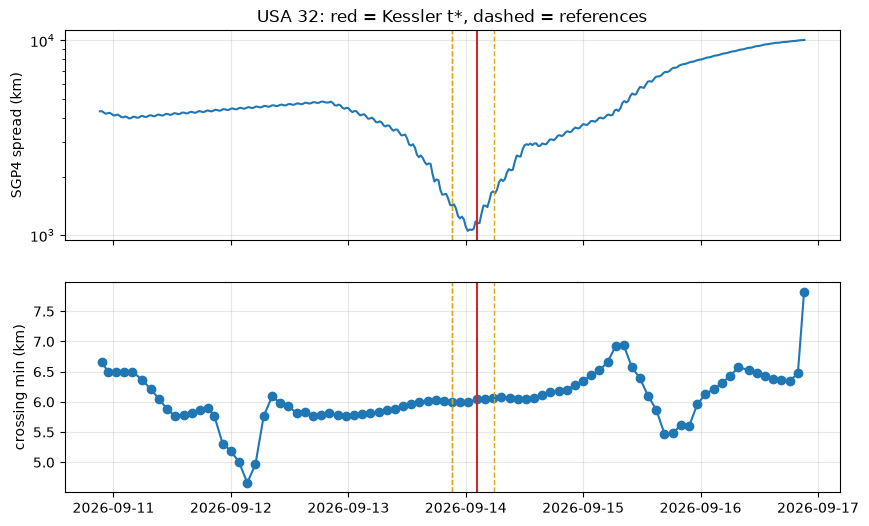

In [3]:
s=json.load(open(B/'site/events/usa-32/summary.json'))
cur=pd.DataFrame(s['solution']['curve']); cur['t']=pd.to_datetime(cur.t)
fig,ax=plt.subplots(2,1,figsize=(10,6),sharex=True)
ax[0].semilogy(cur.t,cur.spread_km); ax[0].set_ylabel('SGP4 spread (km)')
cr=pd.DataFrame(s['solution']['crossings']); cr['t']=pd.to_datetime(cr.t); ax[1].plot(cr.t,cr.km,'o-'); ax[1].set_ylabel('crossing min (km)')
for r in s['references']:
    for a in ax: a.axvline(pd.Timestamp(r['time']),color='goldenrod',ls='--',lw=1)
for a in ax: a.axvline(pd.Timestamp(s['solution']['t_p50']),color='tab:red')
ax[0].set_title('USA 32: red = Kessler t*, dashed = references');

In [4]:
pd.DataFrame(s['solution']['sensitivity'])

,label,t,spread_km,delta_min
0,nearest crossing pass to US Space Forces-Space...,2026-09-13T21:10:20+00:00,5.987000,2.67
1,nearest crossing pass to KeepTrack element-set...,2026-09-14T05:36:00+00:00,6.066000,8.00
2,nearest crossing pass to GCAT debris separatio...,2026-09-13T21:10:20+00:00,5.987000,2.67
3,second element sets,2026-09-14T00:30:11.858400863+00:00,5.835798,NaN


In [5]:
pd.DataFrame(json.load(open(B/'site/events/usa-32/dv.json'))).describe().round(1)

,norad,r,t,n,mag,residual_km
count,18.0,18.0,18.0,18.0,18.0,1.700000e+01
mean,101040.5,333.5,-3015.4,-5.7,3124.3,1.314364e+10
std,5.3,1452.4,4914.1,36.1,5066.5,5.246945e+10
min,101032.0,-42.2,-17114.0,-113.7,10.2,9.400000e+00
25%,101036.2,-19.9,-7437.9,-9.3,30.1,1.280000e+01
50%,101040.5,-5.8,6.9,-1.0,58.3,2.480000e+01
75%,101044.8,-0.2,25.2,0.7,7437.9,5.582960e+06
max,101049.0,6152.6,83.5,80.4,18186.5,2.167074e+11


## Meteor 2-7: separating old debris

24 debris objects share the designator 1981-043. 11 had already reentered before the event. 0 were first catalogued after the reference time. 0 are counted as fragments of this event. Every catalogued piece predates this event (prior breakups: 2004-03). No debris from the new fragmentation has been published in the public catalog yet.


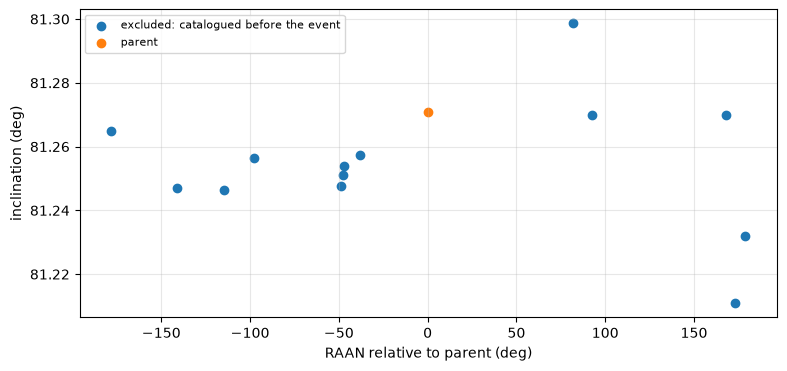

In [6]:
m=json.load(open(B/'site/events/meteor-2-7/summary.json'))['membership']
print(m['explain'])
c=pd.DataFrame(m['clusters'])
fig,ax=plt.subplots(); [ax.scatter(g.x,g.y,label=k) for k,g in c.groupby('assignment')]; ax.set_xlabel('RAAN relative to parent (deg)'); ax.set_ylabel('inclination (deg)'); ax.legend(fontsize=8);

## Synthetic breakup (regression test)
25 fragments with 20 m/s kicks planted in USA 32's orbit, catalogued 2 days later with 5 km along-track noise.

In [7]:
from kessler.forensics.synthetic import make_breakup
from kessler.forensics import epoch_solver, deltav
from kessler.sources import celestrak_gp
gp=celestrak_gp.parse_gp_csv(open(ROOT/'tests/fixtures/gp_current_1988-078.csv').read()); parent=gp[gp.norad_cat_id==19460].iloc[0]
tb=pd.Timestamp('2026-10-15T03:17Z'); p,fr,dvt=make_breakup(parent,tb,seed=3)
sol=epoch_solver.solve(p,fr,tb+pd.Timedelta(minutes=40),n_boot=100)
dv=deltav.fragment_dv(p,fr,sol.t_p50)
print('t* error (s):',(sol.t_p50-tb).total_seconds()); print('median |dv| true / est:',np.median(np.linalg.norm(dvt,axis=1)).round(2), dv.dv_mag.median().round(2))

t* error (s): 0.007258
median |dv| true / est: 31.86 28.25
